# LSTM Multi-Model Text Classifier
> Updated notebook — GloVe embeddings · Train / Val / Test split · Full visualisations

## 1. Imports

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Layer, Embedding, LSTM, Bidirectional,
    Dense, Dropout, Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.initializers import Constant
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, accuracy_score
)

print(f"TensorFlow  : {tf.__version__}")
print(f"GPU devices : {tf.config.list_physical_devices('GPU')}")

TensorFlow  : 2.19.0
GPU devices : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. File Paths

In [3]:
DRIVE_BASE     = '/content/drive/MyDrive/Data'
DATA_PATH      = f'{DRIVE_BASE}/lstm_model_data_v1.csv'
EMBEDDING_PATH = f'{DRIVE_BASE}/glove.6B.100d.txt'
MODEL_SAVE_DIR = f'{DRIVE_BASE}/Models'
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

for path in [DATA_PATH, EMBEDDING_PATH]:
    status = '✅ found' if os.path.exists(path) else '❌ NOT found'
    print(f"{status}  →  {path}")

✅ found  →  /content/drive/MyDrive/Data/lstm_model_data_v1.csv
✅ found  →  /content/drive/MyDrive/Data/glove.6B.100d.txt


## 4. Load Data & EDA

In [4]:
data = pd.read_csv(DATA_PATH)
data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)
print(f"Shape   : {data.shape}")
print(f"Columns : {list(data.columns)}")
data.head()

Shape   : (44196, 2)
Columns : ['processed_text_upto_300_words', 'label']


,processed_text_upto_300_words,label
0,students faculty georgetown law school gathere...,1
1,beirut parliament group lebanon hezbollah said...,1
2,kabul us ambassador afghanistan said monday wo...,1
3,berlin chancellor angela merkel friday said ge...,1
4,easy blame white man way accountable actions l...,0


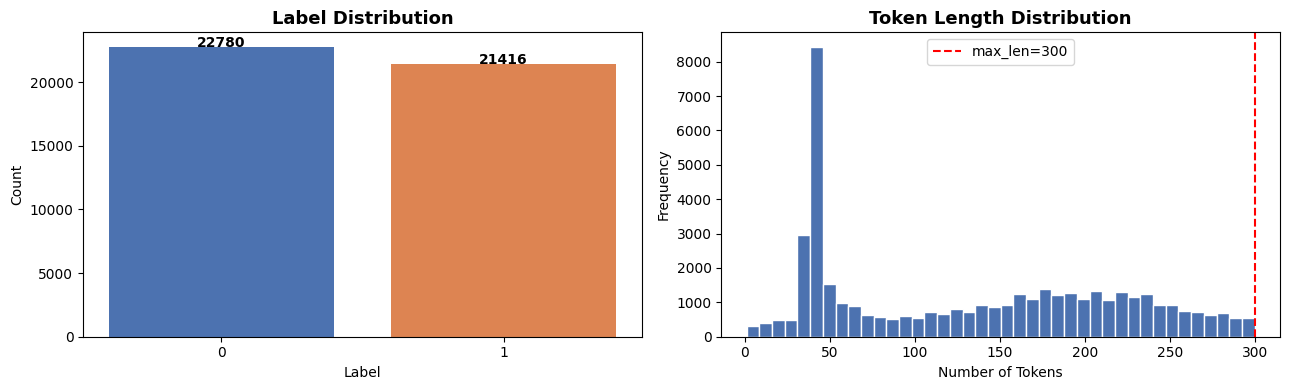

count    44196.0
mean       133.0
std         85.2
min          1.0
25%         43.0
50%        133.0
75%        207.0
max        300.0
Name: text_len, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

label_counts = data['label'].value_counts()
axes[0].bar(label_counts.index.astype(str), label_counts.values, color=['#4C72B0','#DD8452'])
axes[0].set_title('Label Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Label'); axes[0].set_ylabel('Count')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontweight='bold')

data['text_len'] = data['processed_text_upto_300_words'].apply(lambda x: len(str(x).split()))
axes[1].hist(data['text_len'], bins=40, color='#4C72B0', edgecolor='white')
axes[1].axvline(300, color='red', linestyle='--', label='max_len=300')
axes[1].set_title('Token Length Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Tokens'); axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print(data['text_len'].describe().round(1))

## 5. Features & Labels

In [6]:
data_X = data['processed_text_upto_300_words'].astype(str)
data_Y = data['label'].values
print(f"Samples : {len(data_X)}")
print(f"Label distribution: {np.unique(data_Y, return_counts=True)}")

Samples : 44196
Label distribution: (array([0, 1]), array([22780, 21416]))


## 6. Tokenisation

In [7]:
MAX_LEN = 300

tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(data_X)
word_index   = tokenizer.word_index
vocab_length = len(word_index)
print(f"Vocabulary size : {vocab_length:,}")

with open(f'{MODEL_SAVE_DIR}/tokenizer.json', 'w') as f:
    f.write(tokenizer.to_json())
with open(f'{MODEL_SAVE_DIR}/word_index.json', 'w') as f:
    json.dump(word_index, f)
print("Tokenizer saved to Drive ✅")

Vocabulary size : 108,787
Tokenizer saved to Drive ✅


## 7. Pad Sequences

In [8]:
tokenized_text = tokenizer.texts_to_sequences(data_X)
padded_text    = pad_sequences(tokenized_text, maxlen=MAX_LEN, truncating='post', padding='post')
print(f"Padded shape : {padded_text.shape}")

Padded shape : (44196, 300)


## 8. Train / Validation / Test Split
> 70 % train · 15 % validation · 15 % test — stratified

In [9]:
RANDOM_SEED = 42

X_temp, X_test, y_temp, y_test = train_test_split(
    padded_text, data_Y, test_size=0.15, random_state=RANDOM_SEED, stratify=data_Y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.85, random_state=RANDOM_SEED, stratify=y_temp
)

print(f"Train : {X_train.shape}  →  {np.unique(y_train, return_counts=True)}")
print(f"Val   : {X_val.shape}    →  {np.unique(y_val,   return_counts=True)}")
print(f"Test  : {X_test.shape}   →  {np.unique(y_test,  return_counts=True)}")

Train : (30936, 300)  →  (array([0, 1]), array([15946, 14990]))
Val   : (6630, 300)    →  (array([0, 1]), array([3417, 3213]))
Test  : (6630, 300)   →  (array([0, 1]), array([3417, 3213]))


## 9. GloVe Embedding Matrix

In [10]:
EMBEDDING_DIM = 100

embed_dict = {}
with open(EMBEDDING_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        parts = line.split()
        embed_dict[parts[0]] = np.asarray(parts[1:], dtype='float32')

print(f"GloVe vectors loaded : {len(embed_dict):,}")

embedding_matrix = np.zeros((vocab_length + 1, EMBEDDING_DIM), dtype='float32')
covered = missed = 0
for word, idx in word_index.items():
    vec = embed_dict.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        covered += 1
    else:
        missed += 1

print(f"Words covered  : {covered:,}  ({100*covered/(covered+missed):.1f}%)")
print(f"Words missing  : {missed:,}")
print(f"Matrix shape   : {embedding_matrix.shape}")

GloVe vectors loaded : 400,000
Words covered  : 62,655  (57.6%)
Words missing  : 46,132
Matrix shape   : (108788, 100)


## 10. Custom Keras Layers

In [11]:
class InputDividerLayer(Layer):
    """Splits embedded sequence into num_models equal chunks along the time axis."""
    def __init__(self, num_models, **kwargs):
        super().__init__(**kwargs)
        self.num_models = num_models

    def call(self, inputs):
        seq_len = tf.shape(inputs)[1]
        emb_dim = tf.shape(inputs)[2]
        factor  = seq_len // self.num_models
        x = tf.reshape(inputs, (-1, self.num_models, factor, emb_dim))
        return tf.cast(tf.transpose(x, perm=[1, 0, 2, 3]), tf.float32)

    def get_config(self):
        cfg = super().get_config(); cfg.update({'num_models': self.num_models}); return cfg


class BasicTextProcessingLayer(Layer):
    """Stacked LSTM + Dense block for one text chunk."""
    def __init__(self, lstm_layer_config, dense_layer_config, **kwargs):
        super().__init__(**kwargs)
        self.lstm_layer_config  = lstm_layer_config
        self.dense_layer_config = dense_layer_config

        self.lstm_layers = []
        for cfg in lstm_layer_config:
            lstm = LSTM(
                units=cfg['units'],
                activation='tanh',               # tanh is correct; relu risks exploding gradients
                recurrent_activation='sigmoid',
                return_sequences=cfg['return_sequences'],
                dropout=cfg.get('dropout', 0.1),
            )
            self.lstm_layers.append(Bidirectional(lstm) if cfg.get('bidirection') else lstm)

        self.dense_layers = [
            Dense(c['units'], activation=c['activation'],
                  kernel_initializer=c['kernel_initializer'])
            for c in dense_layer_config
        ]

    def call(self, x):
        for l in self.lstm_layers:  x = l(x)
        for l in self.dense_layers: x = l(x)
        return x

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'lstm_layer_config': self.lstm_layer_config,
                    'dense_layer_config': self.dense_layer_config})
        return cfg


class MultiLSTMLayer(Layer):
    """
    Full pipeline:
      Embedding → InputDivider → N parallel LSTM blocks
      → Concatenate → Dense head → sigmoid output
    """
    def __init__(self, basic_text_processing_layer_config, embedding_matrix,
                 num_models, vocab_size, embedding_output_dim, **kwargs):
        super().__init__(**kwargs)
        self.basic_text_processing_layer_config = basic_text_processing_layer_config
        self.num_models           = num_models
        self.vocab_size           = vocab_size
        self.embedding_output_dim = embedding_output_dim
        self._embedding_matrix    = embedding_matrix.tolist()   # for get_config serialisation

        self.embedding_layer = Embedding(
            input_dim=vocab_size,
            output_dim=embedding_output_dim,
            embeddings_initializer=Constant(embedding_matrix),
            trainable=True,
            mask_zero=True
        )

        self.multi_lstm_models = [
            BasicTextProcessingLayer(
                lstm_layer_config=basic_text_processing_layer_config['lstm_layer_config'],
                dense_layer_config=basic_text_processing_layer_config['dense_layer_config']
            )
            for _ in range(num_models)
        ]

        out_units = num_models * basic_text_processing_layer_config['dense_layer_config'][-1]['units']
        self.final_layers = [
            Dense(2 * out_units,    activation='relu',    kernel_initializer='he_uniform'),
            Dropout(0.3),
            Dense(out_units // 2,   activation='relu',    kernel_initializer='he_uniform'),
            Dropout(0.2),
            Dense(64,               activation='relu',    kernel_initializer='he_uniform'),
            Dense(16,               activation='relu',    kernel_initializer='he_uniform'),
            Dense(1,                activation='sigmoid', kernel_initializer='glorot_uniform'),
        ]

    def call(self, inputs, training=False):
        x     = self.embedding_layer(inputs)
        parts = InputDividerLayer(num_models=self.num_models)(x)
        outs  = [self.multi_lstm_models[i](parts[i]) for i in range(self.num_models)]
        out   = Concatenate(axis=-1)(outs)
        for layer in self.final_layers:
            out = layer(out, training=training) if isinstance(layer, Dropout) else layer(out)
        return out

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            'basic_text_processing_layer_config': self.basic_text_processing_layer_config,
            'embedding_matrix':    self._embedding_matrix,
            'num_models':          self.num_models,
            'vocab_size':          self.vocab_size,
            'embedding_output_dim': self.embedding_output_dim,
        })
        return cfg

print("Custom layers defined ✅")

Custom layers defined ✅


## 11. Layer Configuration

In [12]:
NUM_MODELS = 6   # each block sees 300/6 = 50 tokens

basic_text_processing_layer_config = {
    'lstm_layer_config': [
        {'units': 32,  'return_sequences': True,  'bidirection': True,  'dropout': 0.1},
        {'units': 64,  'return_sequences': True,  'bidirection': False, 'dropout': 0.1},
        {'units': 128, 'return_sequences': False, 'bidirection': False, 'dropout': 0.0},
    ],
    'dense_layer_config': [
        {'units': 128, 'activation': 'relu', 'kernel_initializer': 'he_uniform'},
        {'units': 256, 'activation': 'relu', 'kernel_initializer': 'he_uniform'},
    ]
}
print(f"Each LSTM block processes {MAX_LEN // NUM_MODELS} tokens")

Each LSTM block processes 50 tokens


## 12. Build Model

In [13]:
inp = Input(shape=(MAX_LEN,), dtype=tf.int32, name='token_ids')

out = MultiLSTMLayer(
    basic_text_processing_layer_config=basic_text_processing_layer_config,
    embedding_matrix=embedding_matrix,
    num_models=NUM_MODELS,
    vocab_size=vocab_length + 1,
    embedding_output_dim=EMBEDDING_DIM,
    name='multi_lstm'
)(inp)

model = Model(inputs=inp, outputs=out, name='MultiLSTMClassifier')
model.summary(line_length=90)

Model: "MultiLSTMClassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)                │ (None, 300)                  │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ multi_lstm (MultiLSTMLayer)           │ (None, 1)                    │      19,303,345 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 19,303,345 (73.64 MB)

 Trainable params: 19,303,345 (73.64 MB)

 Non-trainable params: 0 (0.00 B)

## 13. Compile

In [14]:
optimizer = Adam(learning_rate=1e-3, beta_1=0.9, beta_2=0.999, clipnorm=1.0)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
    ]
)
print("Model compiled ✅")

Model compiled ✅


## 14. Callbacks

In [15]:
CKPT_PATH = f'{MODEL_SAVE_DIR}/best_model.keras'

callbacks = [
    EarlyStopping(monitor='val_auc', patience=4, mode='max',
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint(filepath=CKPT_PATH, monitor='val_auc',
                    save_best_only=True, mode='max', verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2,
                      min_lr=1e-6, verbose=1),
]
print(f"Best model → {CKPT_PATH}")

Best model → /content/drive/MyDrive/Data/Models/best_model.keras


## 15. Train

In [16]:
BATCH_SIZE = 64
MAX_EPOCHS = 50

history = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=MAX_EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)
print("Training complete ✅")

Epoch 1/50
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8842 - auc: 0.9443 - loss: 0.2671 - precision: 0.8852 - recall: 0.8692
Epoch 1: val_auc improved from None to 0.99519, saving model to /content/drive/MyDrive/Data/Models/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Data/Models/best_model.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 101s 142ms/step - accuracy: 0.9341 - auc: 0.9805 - loss: 0.1751 - precision: 0.9328 - recall: 0.9311 - val_accuracy: 0.9735 - val_auc: 0.9952 - val_loss: 0.0794 - val_precision: 0.9765 - val_recall: 0.9686 - learning_rate: 0.0010
Epoch 2/50
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.9764 - auc: 0.9949 - loss: 0.0753 - precision: 0.9747 - recall: 0.9767
Epoch 2: val_auc did not improve from 0.99519
484/484 ━━━━━━━━━━━━━━━━━━━━ 51s 104ms/step - accuracy: 0.9772 - auc: 0.9954 - loss: 0.0706 - precision: 0.9752 - recall: 0.9779 - val_accuracy: 0.9817 - val_auc: 0.9951 - val_loss: 0.0642 - val_precision: 0.9751 - v

## 16. Training Curves

In [17]:
def plot_history(history):
    hist    = history.history
    epochs  = range(1, len(hist['loss']) + 1)
    pairs   = [
        ('loss','val_loss','Loss','#E74C3C'),
        ('accuracy','val_accuracy','Accuracy','#2ECC71'),
        ('auc','val_auc','AUC','#3498DB'),
        ('precision','val_precision','Precision','#9B59B6'),
        ('recall','val_recall','Recall','#F39C12'),
    ]
    pairs = [(t,v,l,c) for t,v,l,c in pairs if t in hist]

    cols = 3; rows = -(-len(pairs) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4*rows))
    axes = axes.flatten()

    for ax, (tk, vk, label, color) in zip(axes, pairs):
        ax.plot(epochs, hist[tk], color=color, linewidth=2, label=f'Train {label}')
        ax.plot(epochs, hist[vk], color=color, linewidth=2, linestyle='--',
                alpha=0.5, label=f'Val {label}')
        best = (np.argmin if 'loss' in tk else np.argmax)(hist[vk]) + 1
        ax.axvline(best, color='gray', linestyle=':', alpha=0.7, label=f'Best={best}')
        ax.set_title(label, fontsize=12, fontweight='bold')
        ax.set_xlabel('Epoch'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

    for ax in axes[len(pairs):]: ax.set_visible(False)
    plt.suptitle('Training History', fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('/content/training_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_history(history)

## 17. Evaluate on Test Set

In [18]:
results = model.evaluate(X_test, y_test, batch_size=BATCH_SIZE, verbose=0)
print("── Test Set Results ──────────────────────")
for name, val in zip(model.metrics_names, results):
    print(f"  {name:<14}: {val:.4f}")

y_prob = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\n── Classification Report ─────────────────")
print(classification_report(y_test, y_pred, digits=4))

── Test Set Results ──────────────────────
  loss          : 0.0558
  compile_metrics: 0.9816

── Classification Report ─────────────────
              precision    recall  f1-score   support

           0     0.9931    0.9710    0.9819      3417
           1     0.9699    0.9928    0.9812      3213

    accuracy                         0.9816      6630
   macro avg     0.9815    0.9819    0.9816      6630
weighted avg     0.9819    0.9816    0.9816      6630



## 18. Evaluation Visuals — Confusion Matrix & ROC

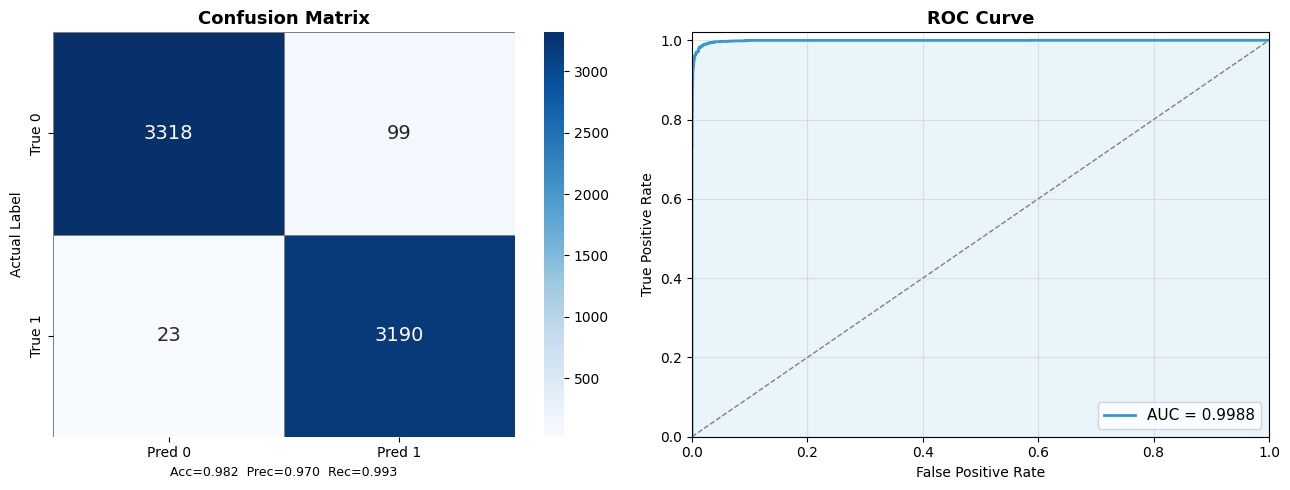

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred 0','Pred 1'], yticklabels=['True 0','True 1'],
            linewidths=0.5, linecolor='gray', annot_kws={'size':14})
axes[0].set_title('Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Actual Label'); axes[0].set_xlabel('Predicted Label')
tn, fp, fn, tp = cm.ravel()
axes[0].set_xlabel(
    f"Acc={accuracy_score(y_test,y_pred):.3f}  Prec={tp/(tp+fp+1e-9):.3f}  Rec={tp/(tp+fn+1e-9):.3f}",
    fontsize=9
)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#3498DB', lw=2, label=f'AUC = {roc_auc:.4f}')
axes[1].plot([0,1],[0,1], color='gray', linestyle='--', lw=1)
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#3498DB')
axes[1].set_xlim([0,1]); axes[1].set_ylim([0,1.02])
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=11); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/evaluation_plots.png', dpi=150, bbox_inches='tight')
plt.show()

## 19. Model Parameter Summary

In [20]:
total     = model.count_params()
trainable = sum(tf.size(v).numpy() for v in model.trainable_variables)

print(f"{'Total parameters':<26}: {total:>12,}")
print(f"{'Trainable parameters':<26}: {trainable:>12,}")
print(f"{'Non-trainable parameters':<26}: {total-trainable:>12,}")
print()
print(f"{'Layer':<42} {'Output Shape':<24} {'Params':>10}")
print('─'*78)
for layer in model.layers:
    try:    shape = str(layer.output_shape)
    except: shape = 'multiple'
    print(f"{layer.name:<42} {shape:<24} {layer.count_params():>10,}")

Total parameters          :   19,303,345
Trainable parameters      :   19,303,345
Non-trainable parameters  :            0

Layer                                      Output Shape                 Params
──────────────────────────────────────────────────────────────────────────────
token_ids                                  multiple                          0
multi_lstm                                 multiple                 19,303,345


## 20. Save to Drive

In [21]:
import shutil

model.save(f'{MODEL_SAVE_DIR}/lstm_model_final.keras')
print(f"Full model saved   : {MODEL_SAVE_DIR}/lstm_model_final.keras")

model.save_weights(f'{MODEL_SAVE_DIR}/lstm_model_weights.weights.h5')
print(f"Weights saved      : {MODEL_SAVE_DIR}/lstm_model_weights.weights.h5")

for plot in ['training_curves.png', 'evaluation_plots.png', 'eda_plots.png']:
    src = f'/content/{plot}'
    if os.path.exists(src):
        shutil.copy(src, f'{MODEL_SAVE_DIR}/{plot}')
        print(f"Plot copied        : {MODEL_SAVE_DIR}/{plot}")

print("All outputs saved to Drive ✅")

Full model saved   : /content/drive/MyDrive/Data/Models/lstm_model_final.keras
Weights saved      : /content/drive/MyDrive/Data/Models/lstm_model_weights.weights.h5
Plot copied        : /content/drive/MyDrive/Data/Models/training_curves.png
Plot copied        : /content/drive/MyDrive/Data/Models/evaluation_plots.png
Plot copied        : /content/drive/MyDrive/Data/Models/eda_plots.png
All outputs saved to Drive ✅


In [23]:
def print_layer_params(layer, indent=0):
    prefix = "  " * indent
    params = layer.count_params()
    try:    shape = str(layer.output_shape)
    except: shape = "multiple"
    print(f"{prefix}{layer.name:<45} {shape:<25} {params:>12,}")

    # Recurse into sub-layers if they exist
    if hasattr(layer, 'layers'):
        for sub in layer.layers:
            print_layer_params(sub, indent + 1)
    elif hasattr(layer, 'lstm_layers') or hasattr(layer, 'dense_layers') \
         or hasattr(layer, 'final_layers') or hasattr(layer, 'multi_lstm_models'):
        for attr in ['embedding_layer','lstm_layers','dense_layers',
                     'multi_lstm_models','final_layers']:
            group = getattr(layer, attr, None)
            if group is None: continue
            if isinstance(group, list):
                for sub in group:
                    print_layer_params(sub, indent + 1)
            else:
                print_layer_params(group, indent + 1)

print(f"{'Layer':<47} {'Output Shape':<25} {'Params':>12}")
print("─" * 90)
for layer in model.layers:
    print_layer_params(layer, indent=0)

Layer                                           Output Shape                    Params
──────────────────────────────────────────────────────────────────────────────────────────
token_ids                                     multiple                             0
multi_lstm                                    multiple                    19,303,345
  embedding                                     multiple                    10,878,800
  basic_text_processing_layer                   multiple                       215,424
    bidirectional                                 multiple                        34,048
    lstm_1                                        multiple                        33,024
    lstm_2                                        multiple                        98,816
    dense                                         multiple                        16,512
    dense_1                                       multiple                        33,024
  basic_text_processing_layer_1  